Подключение библиотек

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
for path in Path("data").rglob("*.csv"):
    print(path)


def safe_divide(numerator, denominator):
    return numerator / denominator.replace(0, np.nan)

data\events.csv
data\listings.csv
data\messages.csv
data\surveys.csv
data\verified.csv
data\data_ONLY_anomailes\events_ONLY_anomailes.csv
data\data_ONLY_anomailes\listings_ONLY_anomailes.csv
data\data_ONLY_anomailes\messages_ONLY_anomailes.csv
data\data_ONLY_anomailes\surveys_ONLY_anomailes.csv
data\data_wthout_anomailes\events_wthout_anomailes.csv
data\data_wthout_anomailes\listings_wthout_anomailes.csv
data\data_wthout_anomailes\messages_wthout_anomailes.csv
data\data_wthout_anomailes\surveys_wthout_anomailes.csv
data\data_ONLY_anomailes\anomalies_bad_time\events_anomalies_bad_time.csv
data\data_ONLY_anomailes\anomalies_bad_time\listings_anomalies_bad_time.csv
data\data_ONLY_anomailes\anomalies_bad_time\messages_anomalies_bad_time.csv
data\data_ONLY_anomailes\anomalies_bad_time\surveys_anomalies_bad_time.csv
data\data_ONLY_anomailes\anomalies_high_listing_ids\events_anomalies_high_listing_ids.csv
data\data_ONLY_anomailes\anomalies_high_listing_ids\listings_anomalies_high_listing_ids.

In [3]:
DATA = Path("data/data_wthout_anomailes")

listings = pd.read_csv(DATA / "listings_wthout_anomailes.csv")
events = pd.read_csv(DATA / "events_wthout_anomailes.csv")
messages = pd.read_csv(DATA / "messages_wthout_anomailes.csv")
surveys = pd.read_csv(DATA / "surveys_wthout_anomailes.csv")

verified = pd.read_csv("data/verified.csv")

tables = {
    "listings": listings,
    "events": events,
    "messages": messages,
    "surveys": surveys,
    "verified": verified
}

for name, df in tables.items():
    print(f"\n{name}: {df.shape}")
    print(df.dtypes)
    print("Дубликатов:", df.duplicated().sum())
    print("Пропуски:")
    print(df.isna().sum())


listings: (15051, 18)
listing_id              int64
seller_id               int64
seller_type               str
category                  str
title                     str
price                   int64
current_price           int64
photos_count            int64
description_length    float64
region                    str
published_at              str
closed_at                 str
close_type                str
views_total             int64
favorites_total         int64
phone_views_total       int64
chats_total             int64
messages_total          int64
dtype: object
Дубликатов: 0
Пропуски:
listing_id              0
seller_id               0
seller_type             0
category              379
title                   0
price                   0
current_price           0
photos_count            0
description_length    449
region                  0
published_at            0
closed_at               0
close_type              0
views_total             0
favorites_total         0
phone_vie

Исследуем listings

In [4]:
display(listings.head())
display(listings.describe().T)

for col in ["seller_type", "category", "region", "close_type"]:
    print(f"\n{col}:")
    print(listings[col].value_counts(dropna=False))

verified_clean = verified[
    verified["listing_id"].isin(listings["listing_id"])
]

print("Всего verified:", len(verified))
print("После очистки:", len(verified_clean))
print(verified_clean["is_deal"].value_counts())

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
0,132065,31904,private,Одежда и обувь,Пуховик женский б/у,570,470,3,130.0,Москва,2026-09-07 19:40:26,2026-09-22 11:05:13,снято продавцом,193,10,0,4,21
1,117997,24387,private,Мебель и интерьер,Комод,2080,2080,6,128.0,СПб,2026-08-22 18:11:20,2026-09-06 17:09:12,снято продавцом,140,6,1,4,25
2,129810,20372,private,Одежда и обувь,Пуховик женский б/у,1320,1320,8,202.0,Москва,2026-09-05 16:07:34,2026-09-08 15:10:57,снято продавцом,50,1,0,4,23
3,111780,13149,private,Спорт и отдых,Спальный мешок,5030,5030,3,82.0,Санкт-Петербург,2026-08-15 14:31:56,2026-09-14 14:31:56,истёк срок,245,9,2,10,44
4,118819,24952,private,Электроника,Смартфон Samsung Galaxy A52 как новый,15880,13340,3,80.0,Санкт-Петербург,2026-08-23 18:13:12,2026-08-26 12:27:38,снято продавцом,11,0,0,1,6


,count,mean,std,min,25%,50%,75%,max
listing_id,15051.0,130630.624543,17672.830473,100004.0,115428.0,130504.0,145960.5,161269.0
seller_id,15051.0,23047.592319,8705.960702,10001.0,15312.0,21986.0,30001.0,41169.0
price,15051.0,7696.746396,8373.611675,120.0,2290.0,4890.0,9945.0,105640.0
current_price,15051.0,7472.874228,8144.042498,120.0,2220.0,4760.0,9635.0,105640.0
photos_count,15051.0,4.236330,2.176351,0.0,3.0,4.0,6.0,10.0
description_length,14602.0,141.496233,126.278364,9.0,65.0,105.0,174.0,1997.0
views_total,15051.0,137.102252,148.104275,0.0,37.0,83.0,189.0,1624.0
favorites_total,15051.0,4.486878,5.053653,0.0,1.0,3.0,6.0,49.0
phone_views_total,15051.0,1.388612,1.919925,0.0,0.0,1.0,2.0,20.0
chats_total,15051.0,5.804664,6.622872,0.0,2.0,3.0,8.0,70.0



seller_type:
seller_type
private     13653
business     1398
Name: count, dtype: int64

category:
category
Электроника              3254
Одежда и обувь           3166
Детские товары           2029
Мебель и интерьер        1872
Запчасти и аксессуары    1541
Бытовая техника          1511
Спорт и отдых            1299
NaN                       379
Name: count, dtype: int64

region:
region
Москва             4110
Санкт-Петербург    2783
Краснодар          1284
Екатеринбург       1233
Новосибирск        1219
Казань             1193
Нижний Новгород    1060
Самара              967
Москва              102
Moscow               91
г. Москва            87
москва               81
краснодар            71
СПб                  66
Питер                62
санкт-петербург      59
г. Краснодар         58
самара               56
г. Казань            55
казань               55
екатеринбург         54
Санкт Петербург      51
Екб                  48
г. Новосибирск       46
нижний новгород      43
новосибирс

Восстановление region

In [5]:
features = listings.copy()

features["region"] = (
    features["region"]
    .str.strip()
    .str.lower()
    .str.replace(r"^г\.\s*", "", regex=True)
)

region_map = {
    "moscow": "москва",
    "масква" : "москва",
    "мск" : "москва",
    "спб": "санкт-петербург",
    "санкт-питербург" : "санкт-петербург",
    "msk" : "москва",
    "питер": "санкт-петербург",
    "санкт петербург": "санкт-петербург",
    "екб": "екатеринбург",
    "новосиб" : "новосибирск",
    "н. новгород": "нижний новгород"
}

features["region"] = features["region"].replace(region_map)

print(features["region"].value_counts())

region
москва             4471
санкт-петербург    3021
краснодар          1413
екатеринбург       1335
новосибирск        1306
казань             1303
нижний новгород    1139
самара             1063
Name: count, dtype: int64


Восстановление category

In [6]:
print("Всего объявлений:", len(features))
print("Уникальных заголовков:", features["title"].nunique())

display(features["title"].value_counts().head(20))

display(
    features.loc[
        features["category"].isna(),
        ["title", "price", "category"]
    ].head(30)
)

title_categories = (
    features.dropna(subset=["category"])
    .groupby("title")["category"]
    .nunique()
)

print(title_categories.value_counts())

features["description_missing"] = (
    features["description_length"].isna().astype(int)
)

Всего объявлений: 15051
Уникальных заголовков: 720


title
Рюкзак городской               93
Кроссовки Nike                 86
Джинсы Levi's                  80
Худи оверсайз                  79
Видеокарта GTX 1660            75
Колонка JBL                    74
Смартфон Samsung Galaxy A52    73
Свитер вязаный                 71
Платье вечернее                71
Сапоги зимние                  70
Наушники беспроводные          68
Костюм мужской                 68
Фотоаппарат Canon              67
Электронная книга              66
Монитор 24 дюйма               63
Пальто шерстяное               62
Игровая приставка              62
Ботинки кожаные                62
iPhone 12 128 ГБ               59
Пуховик женский                59
Name: count, dtype: int64

,title,price,category
6,Наушники беспроводные с документами,7510,NaN
108,Электроплита,11130,NaN
154,Стеллаж,2890,NaN
212,Роутер Wi-Fi новый,12830,NaN
213,iPhone 12 128 ГБ с документами,4680,NaN
282,Кофемашина DeLonghi отличное состояние,10570,NaN
342,Умные часы б/у,15610,NaN
353,Автокресло новый,11960,NaN
402,Смартфон Samsung Galaxy A52 как новый,33270,NaN
425,Видеокарта GTX 1660,7890,NaN


category
1    720
Name: count, dtype: int64


Восстанавливаем категории

In [7]:
title_to_category = (
    features.dropna(subset=["category"])
    .groupby("title")["category"]
    .first()
    .to_dict()
)

features["category"] = features["category"].fillna(
    features["title"].map(title_to_category)
)

print("Осталось пропусков:", features["category"].isna().sum())

Осталось пропусков: 0


Реализация признаков

In [8]:
title = features["title"].str.lower().str.strip()

features["is_used"] = title.str.endswith(" б/у").astype(int)
features["is_new"] = (
    title.str.endswith(" новый")
    & ~title.str.endswith(" как новый")
).astype(int)

features["is_like_new"] = title.str.endswith(" как новый").astype(int)
features["has_documents"] = title.str.endswith(" с документами").astype(int)
features["is_negotiable"] = title.str.endswith(" торг").astype(int)
features["is_urgent"] = title.str.endswith(" срочно").astype(int)
features["is_excellent"] = title.str.endswith(" отличное состояние").astype(int)
features["has_package"] = title.str.contains(
    r"\b(?:коробка|коробкой|упаковка|упаковкой)\b",
    case=False,
    na=False
).astype(int)

suffix_pattern = (
    r"\s+(?:в хорошем состоянии|отличное состояние|"
    r"с документами|как новый|б/у|новый|торг|срочно)$"
)

features["base_title"] = title.str.replace(
    suffix_pattern, "", regex=True
)

features["is_good_condition"] = (
    title.str.endswith(" в хорошем состоянии").astype(int)
)

print("Товарных групп:", features["base_title"].nunique())
print(features["base_title"].value_counts().describe())

print("До:", features["title"].nunique())
print("После:", features["base_title"].nunique())

display(features["base_title"].value_counts().head(20))

# относительная цена

features["product_median_price"] = (
    features.groupby("base_title")["price"].transform("median")
)

features["relative_price"] = (
    features["price"] / features["product_median_price"]
)

features["relative_current_price"] = (
    features["current_price"] / features["product_median_price"]
)

features["log_relative_price"] = np.log(
    features["relative_price"]
)

display(
    features[
        [
            "title",
            "base_title",
            "category",
            "price",
            "product_median_price",
            "relative_price"
        ]
    ].head(15)
)

print(features["relative_price"].describe())

print(
    features["base_title"].value_counts().describe()
)

Товарных групп: 80
count     80.00000
mean     188.13750
std       51.71214
min      108.00000
25%      146.75000
50%      172.50000
75%      231.25000
max      307.00000
Name: count, dtype: float64
До: 720
После: 80


base_title
худи оверсайз             307
кроссовки nike            295
рюкзак городской          294
платье вечернее           288
костюм мужской            278
сапоги зимние             270
джинсы levi's             270
видеокарта gtx 1660       267
пальто шерстяное          260
пуховик женский           258
iphone 12 128 гб          255
наушники беспроводные     252
свитер вязаный            252
колонка jbl               251
ботинки кожаные           250
планшет huawei matepad    249
электронная книга         246
фотоаппарат canon         242
игровая приставка         241
ноутбук lenovo ideapad    235
Name: count, dtype: int64

,title,base_title,category,price,product_median_price,relative_price
0,Пуховик женский б/у,пуховик женский,Одежда и обувь,570,1530.0,0.372549
1,Комод,комод,Мебель и интерьер,2080,6510.0,0.319508
2,Пуховик женский б/у,пуховик женский,Одежда и обувь,1320,1530.0,0.862745
3,Спальный мешок,спальный мешок,Спорт и отдых,5030,5690.0,0.884007
4,Смартфон Samsung Galaxy A52 как новый,смартфон samsung galaxy a52,Электроника,15880,14630.0,1.085441
5,Самокат взрослый как новый,самокат взрослый,Спорт и отдых,5700,4885.0,1.166837
6,Наушники беспроводные с документами,наушники беспроводные,Электроника,7510,14720.0,0.510190
7,Тормозные колодки б/у,тормозные колодки,Запчасти и аксессуары,3500,4015.0,0.871731
8,Багажник на крышу как новый,багажник на крышу,Запчасти и аксессуары,4590,4410.0,1.040816
9,Палатка 4-местная,палатка 4-местная,Спорт и отдых,6280,5880.0,1.068027


count    15051.000000
mean         1.199686
std          0.794045
min          0.068966
25%          0.666667
50%          1.000000
75%          1.495956
max         10.065359
Name: relative_price, dtype: float64
count     80.00000
mean     188.13750
std       51.71214
min      108.00000
25%      146.75000
50%      172.50000
75%      231.25000
max      307.00000
Name: count, dtype: float64


в хорошем состоянии    80
отличное состояние     80
с документами          80
как новый              80
срочно                 80
новый                  80
торг                   80
б/у                    80
Name: count, dtype: int64

(294, 34)


is_deal                                  0            1
price                  mean    8126.277778  8074.912281
                       median  4910.000000  5590.000000
                       std     9368.096581  8715.970312
relative_price         mean       1.390955     1.134301
                       median     1.154834     0.939540
                       std        1.031071     0.740892
relative_current_price mean       1.359186     1.099220
                       median     1.111190     0.910343
                       std        1.025536     0.743792
log_relative_price     mean       0.122212    -0.060085
                       median     0.143841    -0.062411
                       std        0.638216     0.617041

,total,deals,deal_rate
price_group,,,
Очень дешёвый,34,16,0.470588
Дешёвый,65,31,0.476923
Рыночная цена,67,25,0.373134
Дорогой,39,17,0.435897
Очень дорогой,89,25,0.280899


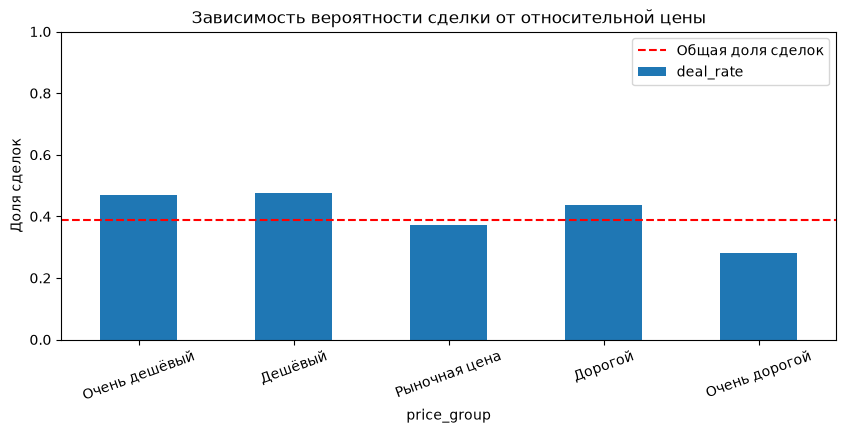

In [9]:
unique_titles = sorted(
    title.dropna().unique(),
    key=len,
    reverse=True
)

suffixes = []

for full_title in unique_titles:
    for short_title in unique_titles:
        if full_title.startswith(short_title + " "):
            suffix = full_title[len(short_title):].strip()
            suffixes.append(suffix)
            break

display(pd.Series(suffixes).value_counts())

research = features.merge(
    verified,
    on="listing_id",
    how="inner"
)

print(research.shape)

display(
    research.groupby("is_deal")[
        [
            "price",
            "relative_price",
            "relative_current_price",
            "log_relative_price"
        ]
    ].agg(["mean", "median", "std"]).T
)

research["price_group"] = pd.cut(
    research["relative_price"],
    bins=[0, 0.5, 0.8, 1.2, 1.5, np.inf],
    labels=[
        "Очень дешёвый",
        "Дешёвый",
        "Рыночная цена",
        "Дорогой",
        "Очень дорогой"
    ]
)

price_stats = (
    research.groupby("price_group", observed=True)
    .agg(
        total=("is_deal", "count"),
        deals=("is_deal", "sum"),
        deal_rate=("is_deal", "mean")
    )
)

display(price_stats)

price_stats["deal_rate"].plot(
    kind="bar",
    figsize=(10, 4),
    rot=20,
    title="Зависимость вероятности сделки от относительной цены"
)

plt.axhline(
    research["is_deal"].mean(),
    color="red",
    linestyle="--",
    label="Общая доля сделок"
)

plt.ylabel("Доля сделок")
plt.ylim(0, 1)
plt.legend()
plt.show()

In [10]:
# Относительная величина снижения цены
features["discount_pct"] = (
    (features["price"] - features["current_price"])
    / features["price"]
)

# Снижалась ли цена к моменту закрытия
features["has_discount"] = (
    features["current_price"] < features["price"]
).astype(int)

# Цена существенно выше медианы
features["is_overpriced"] = (
    features["relative_price"] > 1.5
).astype(int)

# Логарифм абсолютной цены
features["log_price"] = np.log1p(features["price"])

features["published_at"] = pd.to_datetime(
    features["published_at"]
)

features["closed_at"] = pd.to_datetime(
    features["closed_at"]
)

features["lifetime_hours"] = (
    features["closed_at"] - features["published_at"]
).dt.total_seconds() / 3600

features["lifetime_days"] = features["lifetime_hours"] / 24

display(features["lifetime_days"].describe())

features["is_closed_first_day"] = (
    features["lifetime_days"] <= 1
).astype(int)

features["is_closed_first_week"] = (
    features["lifetime_days"] <= 7
).astype(int)

features["log_lifetime"] = np.log1p(
    features["lifetime_days"]
)

research = features.merge(
    verified, on="listing_id", how="inner"
)

display(
    research.groupby("is_deal")["lifetime_days"]
    .agg(["mean", "median", "std", "min", "max"])
)

research["lifetime_group"] = pd.cut(
    research["lifetime_days"],
    bins=[0, 1, 3, 7, 14, 29, np.inf],
    labels=[
        "До 1 дня",
        "1–3 дня",
        "3–7 дней",
        "7–14 дней",
        "14–29 дней",
        "Более 29 дней"
    ],
    include_lowest=True
)

lifetime_stats = (
    research.groupby("lifetime_group", observed=True)
    .agg(
        total=("is_deal", "count"),
        deals=("is_deal", "sum"),
        deal_rate=("is_deal", "mean")
    )
)

display(lifetime_stats)

display(
    research.groupby("close_type")
    .agg(
        total=("is_deal", "count"),
        deals=("is_deal", "sum"),
        deal_rate=("is_deal", "mean")
    )
)

count    15051.000000
mean        14.845349
std         11.829440
min          0.061238
25%          4.137355
50%          9.444769
75%         30.000000
max         30.000000
Name: lifetime_days, dtype: float64

,mean,median,std,min,max
is_deal,,,,,
0,16.524821,11.929664,12.169630,0.590313,30.0
1,12.518215,8.499242,10.580727,0.814468,30.0


,total,deals,deal_rate
lifetime_group,,,
До 1 дня,5,1,0.200000
1–3 дня,38,12,0.315789
3–7 дней,69,38,0.550725
7–14 дней,64,30,0.468750
14–29 дней,14,6,0.428571
Более 29 дней,104,27,0.259615


,total,deals,deal_rate
close_type,,,
заблокировано,2,0,0.000000
истёк срок,104,27,0.259615
снято продавцом,188,87,0.462766


Проверка на дублирование признаков (жизнь более 29 дней)

In [11]:
display(pd.crosstab(
    research["lifetime_group"],
    research["close_type"]
))

close_type,заблокировано,истёк срок,снято продавцом
lifetime_group,,,
До 1 дня,0,0,5
1–3 дня,2,0,36
3–7 дней,0,0,69
7–14 дней,0,0,64
14–29 дней,0,0,14
Более 29 дней,0,104,0


Зависимость времени жизни от сделки только среди объявлений, снятых продавцом

In [12]:
display(
    research[
        research["close_type"] == "снято продавцом"
    ]
    .groupby("lifetime_group", observed=True)["is_deal"]
    .agg(["count", "sum", "mean"])
)

,count,sum,mean
lifetime_group,,,
До 1 дня,5,1,0.200000
1–3 дня,36,12,0.333333
3–7 дней,69,38,0.550725
7–14 дней,64,30,0.468750
14–29 дней,14,6,0.428571


Поведенческие признаки

Относительные признаки

In [13]:
features["messages_per_chat"] = safe_divide(
    features["messages_total"],
    features["chats_total"]
)

features["chats_per_view"] = safe_divide(
    features["chats_total"],
    features["views_total"]
)

features["phones_per_view"] = safe_divide(
    features["phone_views_total"],
    features["views_total"]
)

features["favorites_per_view"] = safe_divide(
    features["favorites_total"],
    features["views_total"]
)

features["contacts_total"] = (
    features["chats_total"]
    + features["phone_views_total"]
)

features["contacts_per_view"] = safe_divide(
    features["contacts_total"],
    features["views_total"]
)

Интенсивность активности

In [14]:
days = features["lifetime_days"].clip(lower=1)

features["views_per_day"] = (
    features["views_total"] / days
)

features["chats_per_day"] = (
    features["chats_total"] / days
)

features["messages_per_day"] = (
    features["messages_total"] / days
)

features["contacts_per_day"] = (
    features["contacts_total"] / days
)

Новые признаки

In [15]:
# относительная популярность товара по просмотрам

features["views_per_day_median"] = (
    features.groupby("base_title")["views_per_day"]
    .transform("median")
)

features["relative_views_per_day"] = safe_divide(
    features["views_per_day"],
    features["views_per_day_median"]
)

# относительная популярность товара по сообщениям

features["median_messages_per_chat"] = (
    features.groupby("base_title")["messages_per_chat"]
    .transform("median")
)

features["relative_messages_per_chat"] = safe_divide(
    features["messages_per_chat"],
    features["median_messages_per_chat"]
)

# относительная популярность товара по длине описания

features["median_description_length"] = (
    features.groupby("base_title")["description_length"]
    .transform("median")
)

features["relative_description_length"] = safe_divide(
    features["description_length"],
    features["median_description_length"]
)

# относительная популярность товара lifetime товара

features["median_lifetime_days"] = (
    features.groupby("base_title")["lifetime_days"]
    .transform("median")
)

features["relative_lifetime_days"] = safe_divide(
    features["lifetime_days"],
    features["median_lifetime_days"]
)

### Анализ опросов продавцов (surveys)

In [16]:
display(surveys.head(10))

print("Размер:", surveys.shape)

print("\nПропуски:")
print(surveys.isna().sum())

print("\nВарианты ответов:")
print(surveys["answer"].value_counts(dropna=False))

print("\nДубликаты строк:")
print(surveys.duplicated().sum())

print("\nПовторяющиеся listing_id:")
print(surveys["listing_id"].duplicated().sum())

survey_conflicts = (
    surveys.groupby("listing_id")["answer"]
    .nunique()
)

display(survey_conflicts.value_counts())

# Разделение ответов по столбцам
answers_count = surveys["answer"].value_counts()

for answer_type in answers_count.index.tolist():
    surveys[f"answer_type_{answer_type}"] = (
        surveys["answer"] == answer_type
    ).astype(int)

# Мог ли продавец получить опрос
features["survey_eligible"] = (
    (features["seller_type"] == "private")
    & (features["close_type"] == "снято продавцом")
).astype(int)

# Есть ли непустой ответ на опрос
features["survey_answered"] = (
    features["listing_id"].isin(
        surveys.loc[surveys["answer"].notna(), "listing_id"]
    )
).astype(int)

# могут ли продавцы врать
survey_research = (
    surveys[["listing_id", "answer"]]
    .drop_duplicates()
    .merge(verified_clean, on="listing_id", how="inner")
)

display(
    survey_research.groupby("answer")
    .agg(
        total=("is_deal", "count"),
        deals=("is_deal", "sum"),
        deal_rate=("is_deal", "mean")
    )
)

display(survey_conflicts.value_counts())

,listing_id,answered_at,platform,answer
0,100227,2026-08-02 10:38:45,ios,Передумал продавать
1,100431,2026-08-02 19:04:57,android,Продал в другом месте
2,100724,2026-08-02 19:49:59,web,Продал в другом месте
3,100551,2026-08-02 19:58:47,android,Передумал продавать
4,100476,2026-08-02 20:23:51,android,Продал в другом месте
5,100729,2026-08-03 08:20:57,android,Продал в другом месте
6,101270,2026-08-03 09:08:28,ios,Продал в другом месте
7,100402,2026-08-03 10:37:32,android,Продал в другом месте
8,100212,2026-08-03 11:56:04,ios,Продал на Авито
9,101248,2026-08-03 15:29:23,web,Продал на Авито


Размер: (5846, 4)

Пропуски:
listing_id     0
answered_at    0
platform       0
answer         0
dtype: int64

Варианты ответов:
answer
Продал на Авито          2439
Продал в другом месте    1641
Передумал продавать      1105
Другая причина            661
Name: count, dtype: int64

Дубликаты строк:
0

Повторяющиеся listing_id:
0


answer
1    5846
Name: count, dtype: int64

,total,deals,deal_rate
answer,,,
Другая причина,16,6,0.375000
Передумал продавать,17,1,0.058824
Продал в другом месте,28,4,0.142857
Продал на Авито,51,41,0.803922


answer
1    5846
Name: count, dtype: int64

Объединение surveys и features

In [17]:
survey_features = [
    col for col in surveys.columns
    if col.startswith("answer_type_")
]

features = features.drop(
    columns=survey_features,
    errors="ignore"
).merge(
    surveys[["listing_id"] + survey_features],
    on="listing_id",
    how="left",
    validate="one_to_one"
)

features[survey_features] = (
    features[survey_features].fillna(0).astype(int)
)

print(features.shape)
print(features["listing_id"].is_unique)

display(
    features[
        survey_features
        + ["survey_eligible", "survey_answered"]
    ].sum()
)

(15051, 66)
True


answer_type_Продал на Авито          2439
answer_type_Продал в другом месте    1641
answer_type_Передумал продавать      1105
answer_type_Другая причина            661
survey_eligible                      9510
survey_answered                      5846
dtype: int64

Анализ событий (events)

In [18]:
display(events.head(15))

print("Размер:", events.shape)

print("\nТипы данных:")
print(events.dtypes)

print("\nПропуски:")
print(events.isna().sum())

print("\nДубликаты:")
print(events.duplicated().sum())

print("\nТипы событий:")
print(events["event_type"].value_counts(dropna=False))

print("\nУникальных покупателей:")
print(events["user_id"].nunique())

print("\nУникальных объявлений:")
print(events["listing_id"].nunique())

display(
    events.groupby("event_type")
    .agg(
        total=("listing_id", "count"),
        unique_listings=("listing_id", "nunique"),
        unique_users=("user_id", "nunique"),
        missing_users=("user_id", lambda x: x.isna().sum()),
        missing_prices=("new_price", lambda x: x.isna().sum())
    )
)

events["event_time"] = pd.to_datetime(
    events["event_time"],
    errors="coerce"
)

print("Некорректных дат:", events["event_time"].isna().sum())

event_check = events.merge(
    features[["listing_id", "published_at", "closed_at"]],
    on="listing_id",
    how="left",
    validate="many_to_one"
)

print(
    "Событий до публикации:",
    (event_check["event_time"] < event_check["published_at"]).sum()
)

print(
    "Событий после закрытия:",
    (event_check["event_time"] > event_check["closed_at"]).sum()
)

print(
    "Событий без соответствующего объявления:",
    event_check["published_at"].isna().sum()
)

,listing_id,event_time,event_type,user_id,new_price
0,100107,2026-08-01 12:00:59,favorite,9000001.0,NaN
1,100117,2026-08-01 12:17:15,chat_start,9000006.0,NaN
2,100031,2026-08-01 12:55:39,phone_view,9000007.0,NaN
3,100021,2026-08-01 12:58:05,favorite,9000014.0,NaN
4,100031,2026-08-01 13:05:30,favorite,9000019.0,NaN
5,100004,2026-08-01 13:28:18,chat_start,9000024.0,NaN
6,100031,2026-08-01 13:29:51,chat_start,9000029.0,NaN
7,100078,2026-08-01 14:14:04,chat_start,9000033.0,NaN
8,100078,2026-08-01 14:22:41,favorite,9000036.0,NaN
9,100220,2026-08-01 14:42:26,chat_start,9000041.0,NaN


Размер: (178737, 5)

Типы данных:
listing_id      int64
event_time        str
event_type        str
user_id       float64
new_price     float64
dtype: object

Пропуски:
listing_id         0
event_time         0
event_type         0
user_id         2939
new_price     175798
dtype: int64

Дубликаты:
0

Типы событий:
event_type
chat_start      87366
favorite        67532
phone_view      20900
price_change     2939
Name: count, dtype: int64

Уникальных покупателей:
65989

Уникальных объявлений:
14575


,total,unique_listings,unique_users,missing_users,missing_prices
event_type,,,,,
chat_start,87366,13611,42673,0,87366
favorite,67532,12444,35556,0,67532
phone_view,20900,8600,14734,0,20900
price_change,2939,2939,0,2939,0


Некорректных дат: 0
Событий до публикации: 27
Событий после закрытия: 0
Событий без соответствующего объявления: 0


In [19]:
events_clean = event_check.loc[
    (event_check["event_time"] >= event_check["published_at"])
    & (event_check["event_time"] <= event_check["closed_at"])
].copy()

print("До очистки:", len(events))
print("После очистки:", len(events_clean))

До очистки: 178737
После очистки: 178710


In [20]:
contact_events = events_clean[
    events_clean["event_type"].isin(
        ["chat_start", "phone_view"]
    )
].copy()

buyer_features = (
    events_clean.groupby("listing_id")
    .agg(
        unique_buyers=("user_id", "nunique"),
        buyer_actions=("user_id", "count")
    )
)

contact_features = (
    contact_events.groupby("listing_id")
    .agg(
        unique_contact_buyers=("user_id", "nunique"),
        contact_actions=("user_id", "count")
    )
)

display(buyer_features.head())
display(contact_features.head())

,unique_buyers,buyer_actions
listing_id,,
100004,22,22
100009,21,21
100012,2,2
100013,3,3
100019,12,12


,unique_contact_buyers,contact_actions
listing_id,,
100004,14,14
100009,13,13
100012,1,1
100013,2,2
100019,7,7


Создание признаков по events

In [21]:
event_features = buyer_features.join(
    contact_features,
    how="left"
).fillna(0)

event_features["actions_per_buyer"] = safe_divide(
    event_features["buyer_actions"],
    event_features["unique_buyers"]
)

event_features["contacts_per_buyer"] = safe_divide(
    event_features["contact_actions"],
    event_features["unique_contact_buyers"]
)

contact_time = (
    contact_events.groupby("listing_id")
    .agg(
        first_contact=("event_time", "min"),
        last_contact=("event_time", "max"),
        published_at=("published_at", "first"),
        closed_at=("closed_at", "first")
    )
)

contact_time["hours_before_first_contact"] = (
    contact_time["first_contact"]
    - contact_time["published_at"]
).dt.total_seconds() / 3600

contact_time["hours_after_last_contact"] = (
    contact_time["closed_at"]
    - contact_time["last_contact"]
).dt.total_seconds() / 3600

contact_time["contact_activity_span"] = (
    contact_time["last_contact"]
    - contact_time["first_contact"]
).dt.total_seconds() / 3600

event_features = event_features.join(
    contact_time[
        [
            "hours_before_first_contact",
            "hours_after_last_contact",
            "contact_activity_span"
        ]
    ],
    how="left"
)

event_columns = event_features.columns.tolist()

features = features.drop(
    columns=event_columns,
    errors="ignore"
).merge(
    event_features.reset_index(),
    on="listing_id",
    how="left",
    validate="one_to_one"
)

count_columns = [
    "unique_buyers",
    "buyer_actions",
    "unique_contact_buyers",
    "contact_actions"
]

features[count_columns] = (
    features[count_columns].fillna(0).astype(int)
)

print(features.shape)
print(features["listing_id"].is_unique)

(15051, 75)
True


Добавление признаков по events

Последнее действие - открытие телефона (гипотеза не подтвердилась, стало хуже)

In [38]:
# последнее действие - открытие телефона
events_dd_by_listing_id = contact_events.sort_values("event_time", ascending=False).drop_duplicates(subset="listing_id", keep="first")

phone_listing_ids = events_dd_by_listing_id.loc[
    events_dd_by_listing_id["event_type"] == "phone_view",
    "listing_id"
]

features["phone_view_is_last_event"] = (
    features["listing_id"].isin(phone_listing_ids)
).astype(int)

display(features["phone_view_is_last_event"].value_counts())


phone_view_is_last_event
0    12023
1     3028
Name: count, dtype: int64

У объявления были и звонковые, и чат-контакты (has_both_contact_types)

In [ ]:

contact_types = (
    contact_events.groupby("listing_id")["event_type"]
    .nunique()
)
both_contacts = contact_types[contact_types == 2]
features["has_both_contact_types"] = (
    features["listing_id"].isin(both_contacts.index)
).astype(int)

Бинарные признаки

In [56]:
features["no_contacts"] = (
    features["contacts_total"] == 0
).astype(int)

features["no_chats"] = (
    features["chats_total"] == 0
).astype(int)

features["no_phone_views"] = (
    features["phone_views_total"] == 0
).astype(int)

features["no_views"] = (
    features["views_total"] == 0
).astype(int)

research = features.merge(
    verified,
    on="listing_id",
    how="inner",
    validate="one_to_one"
)

behavior_features = [
    "messages_per_chat",
    "chats_per_view",
    "phones_per_view",
    "favorites_per_view",
    "contacts_per_view",
    "views_per_day",
    "chats_per_day",
    "messages_per_day",
    "contacts_per_day",
    "no_contacts",
    "no_chats",
    "no_phone_views"
]

display(
    research.groupby("is_deal")[behavior_features]
    .median()
    .T
)

correlations = (
    research.select_dtypes(include="number")
    .drop(columns=["listing_id", "seller_id"])
    .corr()["is_deal"]
    .drop("is_deal")
    .sort_values(key=abs, ascending=False)
)

display(correlations)

is_deal,0,1
messages_per_chat,3.400000,5.100000
chats_per_view,0.039216,0.048059
phones_per_view,0.007463,0.008812
favorites_per_view,0.033333,0.030303
contacts_per_view,0.051515,0.058147
views_per_day,7.633333,9.540257
chats_per_day,0.281109,0.403629
messages_per_day,0.935309,2.366662
contacts_per_day,0.396384,0.524364
no_contacts,0.000000,0.000000


relative_messages_per_chat     0.490899
messages_per_chat              0.486941
messages_per_day               0.426481
answer_type_Продал на Авито    0.391298
survey_eligible                0.205026
                                 ...   
has_documents                  0.003397
price                         -0.002753
is_new                         0.002122
log_price                      0.001445
has_package                         NaN
Name: is_deal, Length: 71, dtype: float64

Создаем первую модель

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [25]:
base_numeric = [
    "price",
    "current_price",
    "photos_count",
    "description_length",
    "views_total",
    "favorites_total",
    "phone_views_total",
    "chats_total",
    "messages_total"
]

categorical = [
    "seller_type",
    "category",
    "region",
    "close_type"
]

price_features = [
    "log_relative_price",
    "relative_current_price",
    "discount_pct",
    "has_discount",
    "log_price"
]

time_features = [
    "lifetime_days",
    "log_lifetime",
    "is_closed_first_week"
]

In [26]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


def evaluate_features(numeric, categorical):

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric),
        ("categorical", categorical_pipeline, categorical)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000))
    ])

    X = research[numeric + categorical]
    y = research["is_deal"]

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=["f1", "precision", "recall", "roc_auc"]
    )

    return {
        "F1": scores["test_f1"].mean(),
        "F1_std": scores["test_f1"].std(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean()
    }

Первый эксперимент

In [27]:
behavior_features = [
    "messages_per_chat",
    "chats_per_view",
    "phones_per_view",
    "favorites_per_view",
    "contacts_per_view",
    "views_per_day",
    "chats_per_day",
    "messages_per_day",
    "contacts_per_day",
    "no_contacts",
    "no_chats",
    "no_phone_views",
    "relative_messages_per_chat",
    "relative_description_length"
]

binary_features = [
    "is_used",
    "is_new",
    "is_like_new",
    "has_documents",
    "is_negotiable",
    "is_urgent",
    "is_excellent",
    "is_good_condition",
    "description_missing",
    "is_overpriced",
    "is_closed_first_day",
    "no_views"
]

# Наш лучший набор признаков (F1 = 0.7256)
all_features = (
    base_numeric
    + price_features
    + time_features
    + behavior_features
)

# Основные эксперименты
experiments = {
    "Baseline": base_numeric,
    "Baseline + Price": base_numeric + price_features,
    "Baseline + Time": base_numeric + time_features,
    "Baseline + Behavior": base_numeric + behavior_features,
    "Baseline + Binary": base_numeric + binary_features,
    "All features without binary": all_features,
    "All features with binary": all_features + binary_features
}

results = pd.DataFrame({
    name: evaluate_features(cols, categorical)
    for name, cols in experiments.items()
}).T

display(results.round(4))


# Проверка каждого бинарного признака отдельно
binary_results = {}

binary_results["Without binary"] = evaluate_features(
    all_features, categorical
)

for feature in binary_features:
    binary_results[feature] = evaluate_features(
        all_features + [feature],
        categorical
    )

binary_results = pd.DataFrame(binary_results).T

# Считаем изменение F1 относительно лучшей модели
binary_results["F1_delta"] = (
    binary_results["F1"]
    - binary_results.loc["Without binary", "F1"]
)

,F1,F1_std,Precision,Recall,ROC_AUC
Baseline,0.6040,0.0544,0.7196,0.5340,0.7730
Baseline + Price,0.6531,0.0540,0.7369,0.6040,0.7785
Baseline + Time,0.6080,0.0610,0.7240,0.5348,0.7672
Baseline + Behavior,0.6858,0.0736,0.7698,0.6308,0.8346
Baseline + Binary,0.6693,0.0499,0.7153,0.6320,0.7700
All features without binary,0.7256,0.0350,0.7848,0.6838,0.8425
All features with binary,0.6967,0.0560,0.7322,0.6668,0.8278


Проверка гипотиз

In [58]:
display(pd.DataFrame({
    "Original": evaluate_features(
        all_features, categorical
    ),
    "With relative_lifetime_days": evaluate_features(
        all_features + ["has_both_contact_types"],
        categorical
    )
}).T.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7256,0.035,0.7848,0.6838,0.8425
With relative_lifetime_days,0.7256,0.035,0.7848,0.6838,0.8425


Проверка слияния с surveys

In [29]:
survey_experiments = {
    "Original": all_features,

    "With survey answers": (
        all_features + survey_features
    ),

    "With all survey features": (
        all_features
        + survey_features
        + ["survey_eligible", "survey_answered"]
    )
}

survey_results = pd.DataFrame({
    name: evaluate_features(cols, categorical)
    for name, cols in survey_experiments.items()
}).T

display(survey_results.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7256,0.0350,0.7848,0.6838,0.8425
With survey answers,0.7264,0.0361,0.7881,0.6755,0.8700
With all survey features,0.7284,0.0344,0.7817,0.6842,0.8715


In [30]:
best_features = (
    all_features
    + survey_features
    + ["survey_eligible", "survey_answered"]
)

Проверка слияния с events

In [31]:
event_buyer_features = [
    "unique_buyers",
    "unique_contact_buyers",
    "actions_per_buyer",
    "contacts_per_buyer"
]

event_time_features = [
    "hours_before_first_contact",
    "hours_after_last_contact",
    "contact_activity_span"
]

event_experiments = {
    "Original": best_features,

    "With buyers": (
        best_features + event_buyer_features
    ),

    "With event time": (
        best_features + event_time_features
    ),

    "With all events": (
        best_features
        + event_buyer_features
        + event_time_features
    )
}

event_results = pd.DataFrame({
    name: evaluate_features(cols, categorical)
    for name, cols in event_experiments.items()
}).T

display(event_results.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7284,0.0344,0.7817,0.6842,0.8715
With buyers,0.7325,0.0282,0.7904,0.6842,0.8883
With event time,0.7439,0.0415,0.8065,0.6929,0.8794
With all events,0.7519,0.0274,0.8231,0.6929,0.8927


In [32]:
event_individual_results = pd.DataFrame({
    col: evaluate_features(
        best_features + [col],
        categorical
    )
    for col in event_buyer_features + event_time_features
}).T

event_individual_results["F1_gain"] = (
    event_individual_results["F1"]
    - event_results.loc["Original", "F1"]
)

display(
    event_individual_results
    .sort_values("F1_gain", ascending=False)
    .round(4)
)

,F1,F1_std,Precision,Recall,ROC_AUC,F1_gain
hours_before_first_contact,0.7370,0.0260,0.7770,0.7020,0.8768,0.0086
contact_activity_span,0.7320,0.0394,0.7898,0.6842,0.8790,0.0036
contacts_per_buyer,0.7291,0.0291,0.7816,0.6842,0.8875,0.0007
unique_buyers,0.7284,0.0344,0.7817,0.6842,0.8717,0.0000
unique_contact_buyers,0.7284,0.0344,0.7817,0.6842,0.8729,0.0000
actions_per_buyer,0.7255,0.0258,0.7732,0.6842,0.8858,-0.0029
hours_after_last_contact,0.7178,0.0576,0.7577,0.6842,0.8741,-0.0106


In [33]:
best_with_events = (
    best_features
    + event_buyer_features
    + event_time_features
)

In [59]:
display(pd.DataFrame({
    "Original": evaluate_features(
        best_with_events, categorical
    ),
    "With both contact types": evaluate_features(
        best_with_events + ["has_both_contact_types"],
        categorical
    )
}).T.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7519,0.0274,0.8231,0.6929,0.8927
With both contact types,0.7519,0.0274,0.8231,0.6929,0.8934


In [60]:
display(research["has_both_contact_types"].value_counts())

display(pd.crosstab(
    research["has_both_contact_types"],
    [research["no_chats"], research["no_phone_views"]]
))

has_both_contact_types
1    164
0    130
Name: count, dtype: int64

no_chats                  0       1    
no_phone_views            0    1  0   1
has_both_contact_types                 
0                         0  106  8  16
1                       164    0  0   0